# Master Model Benchmark & Comparative Analysis: Master Model Benchmark and Comparative Analysis

This unified notebook serves as the single source of truth for comparative analysis across all evaluated modeling paradigms, window scales, quantization formats, and validation strategies in the Philippine Eagle sound classification project.

### Evaluated Paradigms
1. **PCEN CRNN-GRU (From Scratch)**: Temporal-harmonic specialist operating on 128-bin PCEN representations.
2. **MobileNetV3-Small (Vision Transfer)**: Pre-trained ImageNet convolutional feature extractor.
3. **BirdNET MLP Head (Bioacoustic Transfer)**: 1,024-D self-supervised avian foundation embeddings.
4. **Hierarchical Cascade Pipeline**: Multi-stage gate + specialist inference.

### Evaluation Dimensions
- **Window Durations**: 3.0-second vs. 5.0-second sliding windows.
- **Quantization Formats**: Full-precision (FP32) vs. Edge-optimized integer (INT8).
- **Validation Regimes**: Standard leak-free split vs. Leave-One-Site-Out (LOSO Davao del Sur & Cotabato).

## 1. Imports and Configuration

Set up reproducible paths, project root resolution, and visualization aesthetics.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Dynamic Project Root Resolution
def find_project_root():
    p = Path.cwd().resolve()
    while p != p.parent:
        if (p / "data").exists() and (p / "AGENTS.md").exists():
            return p
        p = p.parent
    return Path.cwd().resolve().parent.parent

PROJECT_ROOT = find_project_root()
EXPERIMENTS_DIR = PROJECT_ROOT / "experiments"
EXPERIMENT_DIR = Path.cwd().resolve()
OUTPUTS_DIR = EXPERIMENT_DIR / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# 2. Source Benchmark File Paths (All 5 Paradigms)
CSV_CRNN = EXPERIMENTS_DIR / "crnn-gru-training" / "outputs" / "multiscale-comparison.csv"
CSV_BIGRU_ATTN = EXPERIMENTS_DIR / "crnn-bi-gru-attention-training" / "outputs" / "multiscale-comparison.csv"
CSV_NOISE_MIXING = EXPERIMENTS_DIR / "crnn-bi-gru-attention-noise-mixing" / "outputs" / "multiscale-comparison.csv"
CSV_MOBILENET = EXPERIMENTS_DIR / "mobilenetv3-training" / "outputs" / "multiscale-comparison.csv"
CSV_BIRDNET = EXPERIMENTS_DIR / "birdnet-transfer-learning" / "outputs" / "multiscale-comparison.csv"

# 3. Plotting Style
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["font.size"] = 10
plt.rcParams["figure.dpi"] = 150

print(f"Project root:               {PROJECT_ROOT}")
print(f"Outputs dir:                {OUTPUTS_DIR}")
print(f"CRNN benchmark:             {CSV_CRNN.exists()}")
print(f"BiGRU-Attention benchmark:  {CSV_BIGRU_ATTN.exists()}")
print(f"Noise-Mixing benchmark:     {CSV_NOISE_MIXING.exists()}")
print(f"MobileNet benchmark:        {CSV_MOBILENET.exists()}")
print(f"BirdNET benchmark:          {CSV_BIRDNET.exists()}")


Project root:               /home/fumei/Documents/MachineLearning/EagleSoundClassification
Outputs dir:                /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/model-benchmark/outputs
CRNN benchmark:             True
BiGRU-Attention benchmark:  True
Noise-Mixing benchmark:     True
MobileNet benchmark:        True
BirdNET benchmark:          True


## 2. Ingest and Unify Multi-Paradigm Benchmark Results

Load benchmark metrics from experiments 04, 05, and 06, standardize column schemas, and construct the master comparison DataFrame.

In [ ]:
# Ingest benchmark CSVs from all 5 paradigms and assemble master comparison table
master_csv_path = OUTPUTS_DIR / "master-benchmark.csv"

def normalize_exp_name(raw_name):
    s = str(raw_name).strip()
    # The CRNN-GRU notebook calls its 70/15/15 partition "Recording Split"; the comparison keeps one shared label
    s = s.replace("Recording Split", "Standard Split")
    # Edge-optimized, cost-sensitive and minor-site runs keep their own labels
    if "Edge-Optimized" in s or "Cost-Sensitive" in s or "Minor Sites" in s:
        return s
    if "Standard Split (Focal Loss)" in s:
        return "Standard Split (Focal Loss)"
    elif "Standard" in s:
        return "Standard Split"
    elif "Davao" in s:
        return "LOSO Davao"
    elif "Cotabato" in s:
        return "LOSO Cotabato"
    return s

sources = [
    ("PCEN CRNN-GRU", "From Scratch", CSV_CRNN, 3650.0),
    ("CRNN + Bi-GRU + Attention", "From Scratch", CSV_BIGRU_ATTN, 3700.0),
    ("CRNN + Bi-GRU + Noise Mixing", "From Scratch", CSV_NOISE_MIXING, 3700.0),
    ("MobileNetV3-Small", "Vision Transfer", CSV_MOBILENET, 3800.0),
]

records = []

for arch, paradigm, p, default_fp32_size in sources:
    if p.exists():
        df_src = pd.read_csv(p)
        for _, row in df_src.iterrows():
            scale_str = str(row["Scale"]).strip()
            exp_clean = normalize_exp_name(row["Experiment"])
            
            # 1. FP32 record
            if pd.notna(row.get("FP32 Accuracy")):
                records.append({
                    "Paradigm": paradigm,
                    "Architecture": arch,
                    "Scale": scale_str,
                    "Experiment": exp_clean,
                    "Precision": "FP32",
                    "Accuracy": float(row["FP32 Accuracy"]),
                    "Precision_Score": float(row["Precision"]),
                    "Recall": float(row["Recall"]),
                    "F1_Score": float(row.get("FP32 F1-Score", row.get("F1-Score", 0))),
                    "Specificity": float(row.get("Specificity", np.nan)),
                    "ROC_AUC": float(row["ROC-AUC"]),
                    "Size_KB": default_fp32_size,
                    "Latency_ms": float(row.get("FP16 Latency (ms)", 3.0) * 1.5) if pd.notna(row.get("FP16 Latency (ms)")) else np.nan
                })
            
            # 2. Float16 record (Standard Splits)
            if pd.notna(row.get("FP16 Accuracy")) and float(row.get("FP16 Accuracy", 0)) > 0:
                records.append({
                    "Paradigm": paradigm,
                    "Architecture": arch,
                    "Scale": scale_str,
                    "Experiment": exp_clean,
                    "Precision": "Float16",
                    "Accuracy": float(row["FP16 Accuracy"]),
                    "Precision_Score": float(row["Precision"]),
                    "Recall": float(row["Recall"]),
                    "F1_Score": float(row.get("FP16 F1-Score", row.get("F1-Score", 0))),
                    "Specificity": float(row.get("Specificity", np.nan)),
                    "ROC_AUC": float(row["ROC-AUC"]),
                    "Size_KB": float(row.get("FP16 Size (KB)", 700.0)),
                    "Latency_ms": float(row.get("FP16 Latency (ms)", np.nan))
                })
                
            # 3. INT8 record (Standard Splits)
            if pd.notna(row.get("INT8 Accuracy")) and float(row.get("INT8 Accuracy", 0)) > 0:
                records.append({
                    "Paradigm": paradigm,
                    "Architecture": arch,
                    "Scale": scale_str,
                    "Experiment": exp_clean,
                    "Precision": "INT8",
                    "Accuracy": float(row["INT8 Accuracy"]),
                    "Precision_Score": float(row["Precision"]),
                    "Recall": float(row["Recall"]),
                    "F1_Score": float(row.get("INT8 F1-Score", row.get("F1-Score", 0))),
                    "Specificity": float(row.get("Specificity", np.nan)),
                    "ROC_AUC": float(row["ROC-AUC"]),
                    "Size_KB": float(row.get("INT8 Size (KB)", 500.0)),
                    "Latency_ms": float(row.get("INT8 Latency (ms)", np.nan))
                })

# Ingest BirdNET
if CSV_BIRDNET.exists():
    df_bn = pd.read_csv(CSV_BIRDNET)
    for _, row in df_bn.iterrows():
        records.append({
            "Paradigm": "Bioacoustic Transfer",
            "Architecture": "BirdNET + Head",
            "Scale": "3.0s",
            "Experiment": normalize_exp_name(row["Experiment"]),
            "Precision": row["Precision"],
            "Accuracy": float(row["Accuracy"]),
            "Precision_Score": float(row["Precision_Score"]),
            "Recall": float(row["Recall"]),
            "F1_Score": float(row["F1_Score"]),
            "Specificity": np.nan,
            "ROC_AUC": float(row["ROC_AUC"]),
            "Size_KB": float(row["Size_KB"]),
            "Latency_ms": np.nan
        })

df_master = pd.DataFrame(records)
df_master.to_csv(master_csv_path, index=False)
print(f"Successfully assembled and saved {len(df_master)} master records to: {master_csv_path}")


## 3. Top Edge Models Leaderboard (Standard Split)

Filter and rank candidate edge deployment models on the Standard validation split based on F1-Score, INT8 retention, and memory footprint.

In [ ]:
# 1. Standard Split Edge Deployment Leaderboard
std_df = df_master[df_master["Experiment"].isin(["Standard Split", "Standard Split (Focal Loss)", "Standard Split (Cost-Sensitive)"])].copy()

std_display = std_df[
    ["Paradigm", "Architecture", "Scale", "Experiment", "Precision", "Accuracy", "Precision_Score", "Recall", "F1_Score", "ROC_AUC", "Size_KB", "Latency_ms"]
].copy()

std_display["Accuracy"] = std_display["Accuracy"].map(lambda x: f"{x * 100:.2f}%")
std_display["Precision_Score"] = std_display["Precision_Score"].map(lambda x: f"{x * 100:.2f}%")
std_display["Recall"] = std_display["Recall"].map(lambda x: f"{x * 100:.2f}%")
std_display["F1_Score"] = std_display["F1_Score"].map(lambda x: f"{x:.4f}")
std_display["ROC_AUC"] = std_display["ROC_AUC"].map(lambda x: f"{x:.4f}")
std_display["Size_KB"] = std_display["Size_KB"].map(lambda x: f"{x:6.1f} KB" if pd.notna(x) else "N/A")
std_display["Latency_ms"] = std_display["Latency_ms"].map(lambda x: f"{x:5.2f} ms" if pd.notna(x) else "N/A")

std_display = std_display.sort_values(by="F1_Score", ascending=False)

print("=" * 115)
print("1. PRODUCTION EDGE DEPLOYMENT LEADERBOARD (Standard Split - FP32, Float16, INT8)")
print("=" * 115)
display(std_display)

# 2. Cross-Site Generalization Leaderboard (LOSO Splits - FP32)
loso_df = df_master[
    (df_master["Experiment"].isin(["LOSO Davao", "LOSO Cotabato"])) &
    (df_master["Precision"] == "FP32")
].copy()

loso_display = loso_df[
    ["Architecture", "Scale", "Experiment", "Accuracy", "Precision_Score", "Recall", "F1_Score", "ROC_AUC"]
].copy()
loso_display["Accuracy"] = loso_display["Accuracy"].map(lambda x: f"{x * 100:.2f}%")
loso_display["Precision_Score"] = loso_display["Precision_Score"].map(lambda x: f"{x * 100:.2f}%")
loso_display["Recall"] = loso_display["Recall"].map(lambda x: f"{x * 100:.2f}%")
loso_display["F1_Score"] = loso_display["F1_Score"].map(lambda x: f"{x:.4f}")
loso_display["ROC_AUC"] = loso_display["ROC_AUC"].map(lambda x: f"{x:.4f}")
loso_display = loso_display.sort_values(by=["Experiment", "F1_Score"], ascending=[True, False])

print()
print("=" * 115)
print("2. CROSS-SITE GENERALIZATION LEADERBOARD (Leave-One-Site-Out Evaluation)")
print("=" * 115)
display(loso_display)


## 4. Multi-Paradigm Performance Comparison (3.0s Models)

Generate comparative grouped bar charts showing F1-Score across the three paradigms across Standard, LOSO Davao del Sur, and LOSO Cotabato splits.

Saved paradigm comparison figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/model-benchmark/outputs/figures/paradigm-comparison.png


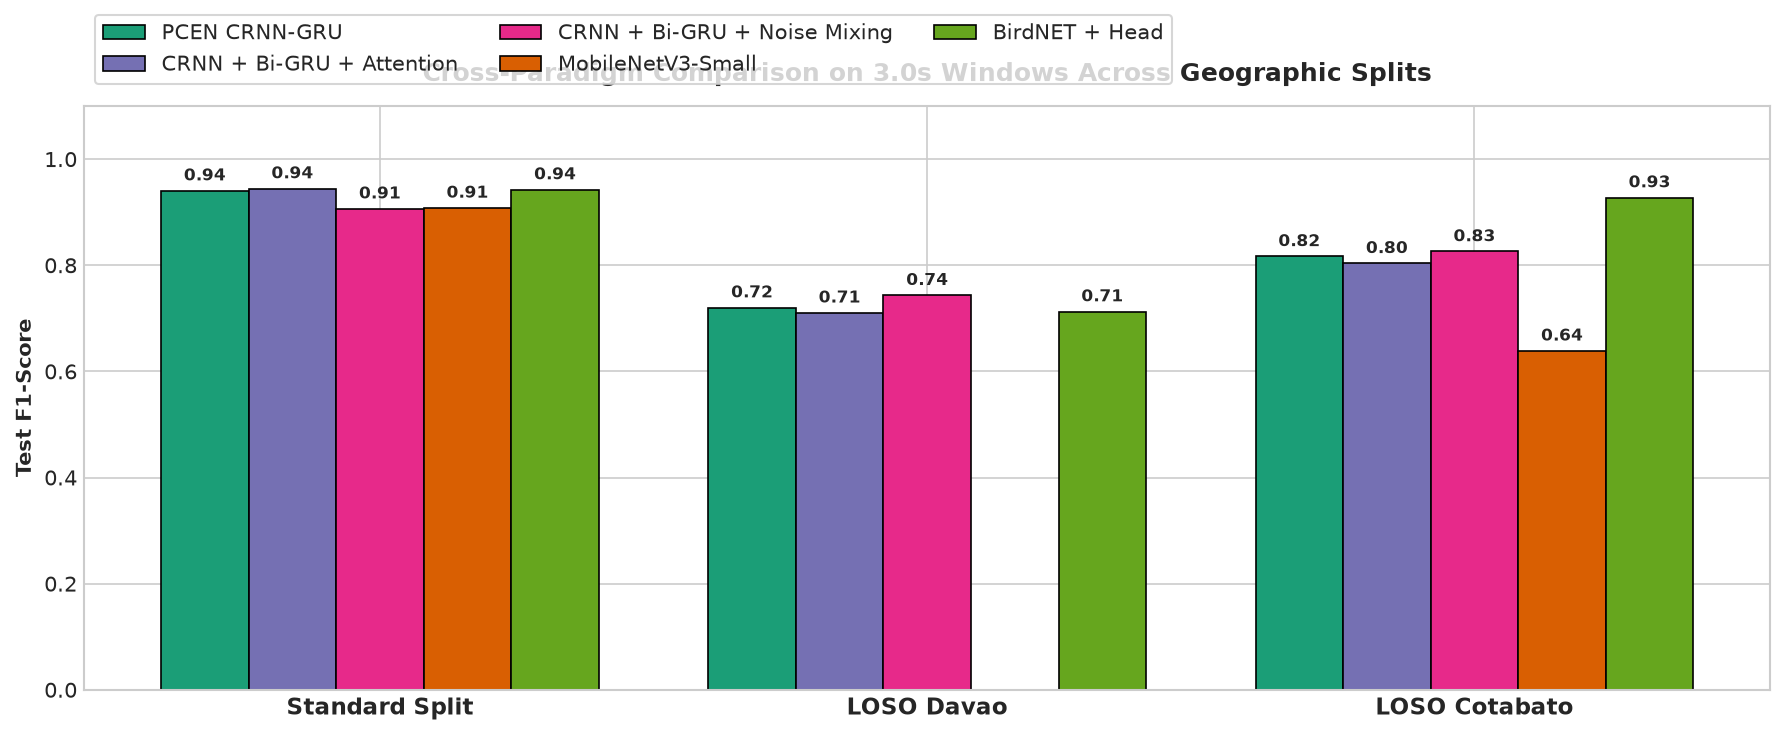

In [4]:
# Filter 3.0s FP32 models across all paradigms for cross-site comparison
plot_df = df_master[
    (df_master["Precision"] == "FP32") &
    (df_master["Scale"].str.contains("3.0s")) &
    (df_master["Experiment"].isin(["Standard Split", "LOSO Davao", "LOSO Cotabato"]))
].copy()

fig, ax = plt.subplots(figsize=(12, 5))
experiments = ["Standard Split", "LOSO Davao", "LOSO Cotabato"]
x = np.arange(len(experiments))

arch_list = [
    ("PCEN CRNN-GRU", "#1b9e77"),
    ("CRNN + Bi-GRU + Attention", "#7570b3"),
    ("CRNN + Bi-GRU + Noise Mixing", "#e7298a"),
    ("MobileNetV3-Small", "#d95f02"),
    ("BirdNET + Head", "#66a61e")
]

total_bars = len(arch_list)
width = 0.8 / total_bars

for i, (arch_name, col) in enumerate(arch_list):
    f1_vals = []
    for exp in experiments:
        sub = plot_df[(plot_df["Architecture"] == arch_name) & (plot_df["Experiment"] == exp)]
        val = sub["F1_Score"].values[0] if len(sub) > 0 else 0.0
        f1_vals.append(val)
    
    offset = (i - (total_bars - 1) / 2) * width
    bars = ax.bar(x + offset, f1_vals, width, label=arch_name, color=col, edgecolor="black", linewidth=0.8)
    
    for b in bars:
        h = b.get_height()
        if h > 0:
            ax.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_ylabel("Test F1-Score", fontweight="bold")
ax.set_title("Cross-Paradigm Comparison on 3.0s Windows Across Geographic Splits", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(experiments, fontweight="bold", fontsize=11)
ax.set_ylim([0.0, 1.1])
ax.legend(frameon=True, loc="lower left", bbox_to_anchor=(0.0, 1.02), ncol=3)

plt.tight_layout()
fig_path = FIGURES_DIR / "paradigm-comparison.png"
fig.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"Saved paradigm comparison figure to: {fig_path}")
plt.show()


## 5. INT8 Edge Quantization Resilience

Evaluate the impact of post-training integer quantization (INT8) across architectures on standard split accuracy and F1 score.

Saved quantization degradation figure to: /home/fumei/Documents/MachineLearning/EagleSoundClassification/experiments/model-benchmark/outputs/figures/quantization-degradation.png


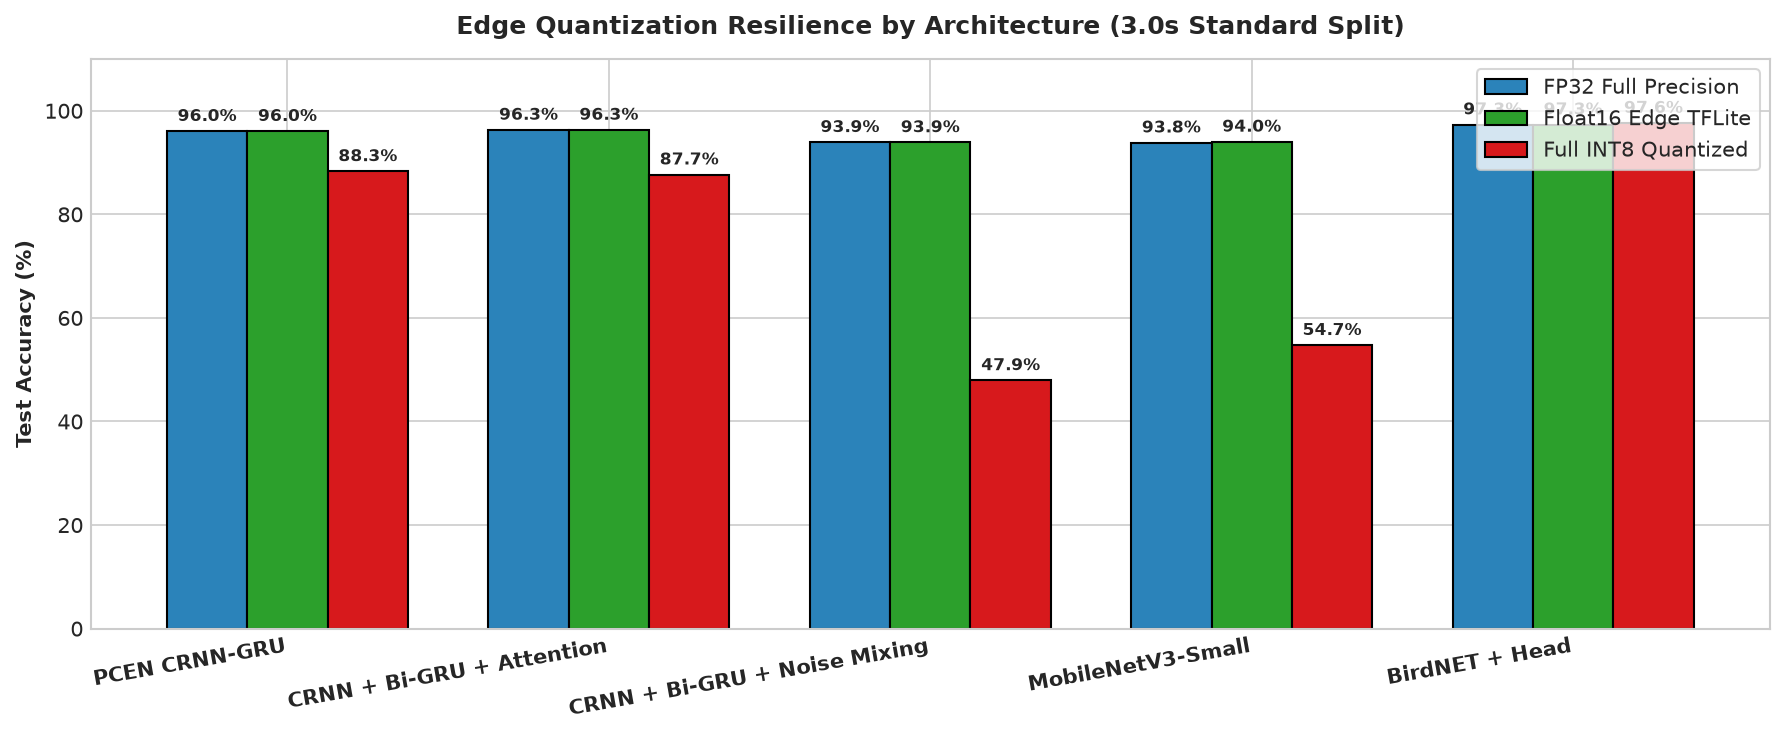

In [5]:
# Compare FP32 vs Float16 vs INT8 for 3.0s Standard Split
q_df = df_master[
    (df_master["Scale"].str.contains("3.0s")) &
    (df_master["Experiment"] == "Standard Split")
].copy()

fig, ax = plt.subplots(figsize=(12, 5))
archs = ["PCEN CRNN-GRU", "CRNN + Bi-GRU + Attention", "CRNN + Bi-GRU + Noise Mixing", "MobileNetV3-Small", "BirdNET + Head"]
x = np.arange(len(archs))
width = 0.25

fp32_scores = [q_df[(q_df["Architecture"] == a) & (q_df["Precision"] == "FP32")]["Accuracy"].values[0] * 100 if len(q_df[(q_df["Architecture"] == a) & (q_df["Precision"] == "FP32")]) > 0 else 0.0 for a in archs]
fp16_scores = [q_df[(q_df["Architecture"] == a) & (q_df["Precision"] == "Float16")]["Accuracy"].values[0] * 100 if len(q_df[(q_df["Architecture"] == a) & (q_df["Precision"] == "Float16")]) > 0 else (fp32_scores[i] if a == "BirdNET + Head" else 0.0) for i, a in enumerate(archs)]
int8_scores = [q_df[(q_df["Architecture"] == a) & (q_df["Precision"] == "INT8")]["Accuracy"].values[0] * 100 if len(q_df[(q_df["Architecture"] == a) & (q_df["Precision"] == "INT8")]) > 0 else 0.0 for a in archs]

bars1 = ax.bar(x - width, fp32_scores, width, label="FP32 Full Precision", color="#2b83ba", edgecolor="black")
bars2 = ax.bar(x, fp16_scores, width, label="Float16 Edge TFLite", color="#2ca02c", edgecolor="black")
bars3 = ax.bar(x + width, int8_scores, width, label="Full INT8 Quantized", color="#d7191c", edgecolor="black")

ax.set_ylabel("Test Accuracy (%)", fontweight="bold")
ax.set_title("Edge Quantization Resilience by Architecture (3.0s Standard Split)", fontweight="bold", pad=12)
ax.set_xticks(x)
ax.set_xticklabels(archs, fontweight="bold", rotation=10, ha="right")
ax.set_ylim([0, 110])
ax.legend(frameon=True, loc="upper right")

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        h = bar.get_height()
        if h > 0:
            ax.annotate(f"{h:.1f}%", xy=(bar.get_x() + bar.get_width() / 2, h),
                        xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8, fontweight="bold")

plt.tight_layout()
q_fig_path = FIGURES_DIR / "quantization-degradation.png"
fig.savefig(q_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved quantization degradation figure to: {q_fig_path}")
plt.show()


## 6. Edge Efficiency Frontier (Model Footprint vs. F1-Score)

Visualize the deployment trade-off between model storage footprint (KB) and classification F1-Score.

In [ ]:
# Scatter plot: Model Size vs F1 Score for Standard Split models
scatter_df = df_master[
    (df_master["Experiment"].isin(["Standard Split", "Standard Split (Focal Loss)", "Standard Split (Cost-Sensitive)"])) &
    (df_master["Size_KB"].notna()) &
    (df_master["Precision"].isin(["FP32", "Float16", "INT8"]))
].copy()
scatter_df["Size_KB"] = scatter_df["Size_KB"].astype(float)

fig, ax = plt.subplots(figsize=(10, 6))
palette = {"FP32": "#2b83ba", "Float16": "#2ca02c", "INT8": "#d7191c"}
markers = {"PCEN CRNN-GRU": "o", "CRNN + Bi-GRU + Attention": "s", "CRNN + Bi-GRU + Noise Mixing": "^", "MobileNetV3-Small": "D", "BirdNET + Head": "v"}

for _, row in scatter_df.iterrows():
    p = row["Precision"]
    arch = row["Architecture"]
    focal_tag = " (Focal)" if "Focal" in row["Experiment"] else ""
    m = markers.get(arch, "o")
    ax.scatter(row["Size_KB"], row["F1_Score"], color=palette.get(p, "gray"), s=140, marker=m, edgecolor="black", linewidth=1.2, zorder=3, alpha=0.9)
    label = f"{arch}{focal_tag} ({row['Scale']}-{p})"
    ax.annotate(label, xy=(row["Size_KB"], row["F1_Score"]), xytext=(5, 4), textcoords="offset points", fontsize=7.5)

ax.set_xlabel("Model Storage Footprint (KB)", fontweight="bold")
ax.set_ylabel("Test F1-Score", fontweight="bold")
ax.set_title("ESP32-S3 Edge Efficiency Frontier: Model Footprint vs. F1-Score", fontweight="bold", pad=12)
ax.set_ylim([0.45, 1.02])
ax.axhline(0.90, color="green", linestyle="--", alpha=0.5, label="Target 0.90 F1 Threshold")
ax.axvline(1000.0, color="orange", linestyle=":", alpha=0.6, label="1 MB Embedded RAM Limit")

# Custom legend for Precision format
for p_label, p_col in palette.items():
    ax.scatter([], [], color=p_col, s=100, label=f"{p_label} Format", edgecolor="black")
ax.legend(frameon=True, loc="lower right", fontsize=9)

plt.tight_layout()
frontier_fig_path = FIGURES_DIR / "edge-efficiency-frontier.png"
fig.savefig(frontier_fig_path, dpi=300, bbox_inches="tight")
print(f"Saved efficiency frontier figure to: {frontier_fig_path}")
plt.show()
